# A material library for imaging: Python, C (gcc) and CUDA (nvcc)

## In plain words

Every piece of glass or crystal in an imaging setup (lenses, windows, the dispersive fiber of a time-stretch camera, the lithium niobate modulator) slows light by a different amount for each color. One six-number formula, the **Sellmeier equation**, captures that for each material. This notebook:

1. derives everything else (group index, dispersion $\beta_2$ and $D$, Abbe number) from that formula with **SymPy**,
2. tabulates and plots six materials from `dgs/materials.py`,
3. applies it to three imaging questions: **color blur in a lens**, **reflection loss in a window**, and the **wavelength-to-time map of time-stretch (STEAM) imaging**,
4. runs the same library in **C with gcc** and in **CUDA with nvcc**, and checks all three agree,
5. ends with a short **grammar for units and signs**, the conventions that keep dispersion numbers from being off by a sign or a factor of $10^{27}$.

| Material | Where it is in an imaging setup | Source |
|---|---|---|
| fused silica | fiber, UV/IR windows, objectives | Malitson 1965 [1] |
| N-BK7 | the default lens and prism glass | SCHOTT [2] |
| sapphire (ordinary ray) | hard windows, Ti:sapphire lasers | Malitson & Dodge 1972 [3] |
| CaF₂ | low-dispersion (apochromatic) lenses | Malitson 1963 [4] |
| LiNbO₃ (e and o) | electro-optic modulators | Zelmon 1997 [5] |

In [1]:
import os, sys, glob, shutil, subprocess, tempfile, pathlib, time
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = pathlib.Path.cwd() if (pathlib.Path.cwd() / 'dgs').exists() else pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))
from dgs import materials as M
sp.init_printing(use_latex='mathjax')
OKABE_ITO = ['#000000', '#E69F00', '#56B4E9', '#009E73', '#D55E00', '#CC79A7']
STYLES = ['-', '--', '-.', ':', (0, (5, 1, 1, 1)), (0, (1, 1))]
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
print('materials:', ', '.join(M.LIBRARY))

materials: fused_silica, n_bk7, sapphire_o, caf2, linbo3_e, linbo3_o


---
## 1. From one formula to every dispersion quantity (SymPy)

$$n^2(\lambda) = 1 + \sum_{i=1}^{3}\frac{B_i\lambda^2}{\lambda^2 - C_i}$$

- **Group index** $n_g = n - \lambda\,\dfrac{dn}{d\lambda}$: a pulse's envelope travels at $c/n_g$.
- **GVD** $\beta_2 = \dfrac{\lambda^3}{2\pi c^2}\dfrac{d^2n}{d\lambda^2}$: how fast a pulse spreads.
- **Dispersion parameter** $D = -\dfrac{\lambda}{c}\dfrac{d^2n}{d\lambda^2}$: the same physics in fiber units.

The library uses closed-form derivatives for speed. SymPy checks them against its own symbolic differentiation and then writes the C code.

In [2]:
lam = sp.symbols('lambda', positive=True)
B = sp.symbols('B1:4', positive=True); C = sp.symbols('C1:4', positive=True)
f = 1 + sum(Bi*lam**2/(lam**2 - Ci) for Bi, Ci in zip(B, C))
print('n^2 ='); display(f)
f1_closed = sum(-2*Bi*Ci*lam/(lam**2 - Ci)**2 for Bi, Ci in zip(B, C))
f2_closed = sum(2*Bi*Ci*(3*lam**2 + Ci)/(lam**2 - Ci)**3 for Bi, Ci in zip(B, C))
print("d(n^2)/dlambda: SymPy minus the library's closed form =", sp.simplify(sp.diff(f, lam) - f1_closed))
print("d2(n^2)/dlambda2: SymPy minus the library's closed form =", sp.simplify(sp.diff(f, lam, 2) - f2_closed))
m_bk7 = M.get('n_bk7')
nexpr = sp.sqrt(f).subs(dict(zip(B, m_bk7.B)) | dict(zip(C, m_bk7.C)))
print(f"N-BK7 at 800 nm: SymPy d2n/dlam2 = {float(sp.diff(nexpr, lam, 2).subs(lam, 0.8)):.10f} um^-2, "
      f"library = {float(M.dn_dlam('n_bk7', 0.8)[1]):.10f} um^-2")
print('\nthe C line SymPy generates for one Sellmeier term (compare dgs/c/materials/materials.h):')
print(sp.ccode(sp.diff(B[0]*lam**2/(lam**2 - C[0]), lam).simplify(), assign_to='f1_term'))

n^2 =


     2          2          2      
 B₁⋅λ       B₂⋅λ       B₃⋅λ       
──────── + ──────── + ──────── + 1
       2          2          2    
-C₁ + λ    -C₂ + λ    -C₃ + λ     

d(n^2)/dlambda: SymPy minus the library's closed form = 0


d2(n^2)/dlambda2: SymPy minus the library's closed form = 0
N-BK7 at 800 nm: SymPy d2n/dlam2 = 0.0492481880 um^-2, library = 0.0492481880 um^-2

the C line SymPy generates for one Sellmeier term (compare dgs/c/materials/materials.h):


f1_term = -2*B1*C1*lambda/pow(C1 - pow(lambda, 2), 2);


---
## 2. The library at a glance

In [3]:
for lam0, label in ((1.55, '1550 nm (telecom, time-stretch)'), (0.8, '800 nm (Ti:sapphire, bio-imaging)')):
    rows = ['| material | n | n_g | β₂ (ps²/km) | D (ps/(nm·km)) | Abbe V_d | R per surface |', '|---|---|---|---|---|---|---|']
    for r in M.table(lam0):
        rows.append(f'| {r[0]} | {r[1]:.5f} | {r[2]:.5f} | {r[3]:+.2f} | {r[4]:+.2f} | {r[5]:.2f} | {100*r[6]:.2f}% |')
    display(Markdown(f'**At {label}**\n\n' + '\n'.join(rows)))
print('zero-dispersion wavelengths:', {k: (round(v, 4) if (v := M.zero_dispersion_um(k)) else None) for k in M.LIBRARY})

**At 1550 nm (telecom, time-stretch)**

| material | n | n_g | β₂ (ps²/km) | D (ps/(nm·km)) | Abbe V_d | R per surface |
|---|---|---|---|---|---|---|
| fused_silica | 1.44402 | 1.46260 | -27.95 | +21.91 | 67.82 | 3.30% |
| n_bk7 | 1.50065 | 1.52007 | -24.63 | +19.31 | 64.17 | 4.01% |
| sapphire_o | 1.74618 | 1.77317 | -32.52 | +25.50 | 72.31 | 7.38% |
| caf2 | 1.42602 | 1.43326 | -0.07 | +0.06 | 95.00 | 3.08% |
| linbo3_e | 2.13756 | 2.18232 | +99.49 | -78.00 | 20.53 | 13.15% |
| linbo3_o | 2.21111 | 2.26368 | +112.19 | -87.96 | 18.74 | 14.23% |

**At 800 nm (Ti:sapphire, bio-imaging)**

| material | n | n_g | β₂ (ps²/km) | D (ps/(nm·km)) | Abbe V_d | R per surface |
|---|---|---|---|---|---|---|
| fused_silica | 1.45332 | 1.46714 | +36.16 | -106.43 | 67.82 | 3.41% |
| n_bk7 | 1.51078 | 1.52665 | +44.65 | -131.42 | 64.17 | 4.14% |
| sapphire_o | 1.76013 | 1.78155 | +58.04 | -170.82 | 72.31 | 7.58% |
| caf2 | 1.43053 | 1.43890 | +27.87 | -82.04 | 95.00 | 3.14% |
| linbo3_e | 2.17547 | 2.26422 | +368.25 | -1083.84 | 20.53 | 13.70% |
| linbo3_o | 2.25528 | 2.35852 | +430.01 | -1265.60 | 18.74 | 14.87% |

zero-dispersion wavelengths: {'fused_silica': 1.2728, 'n_bk7': 1.322, 'sapphire_o': 1.3144, 'caf2': 1.5482, 'linbo3_e': 1.9134, 'linbo3_o': 1.8986}


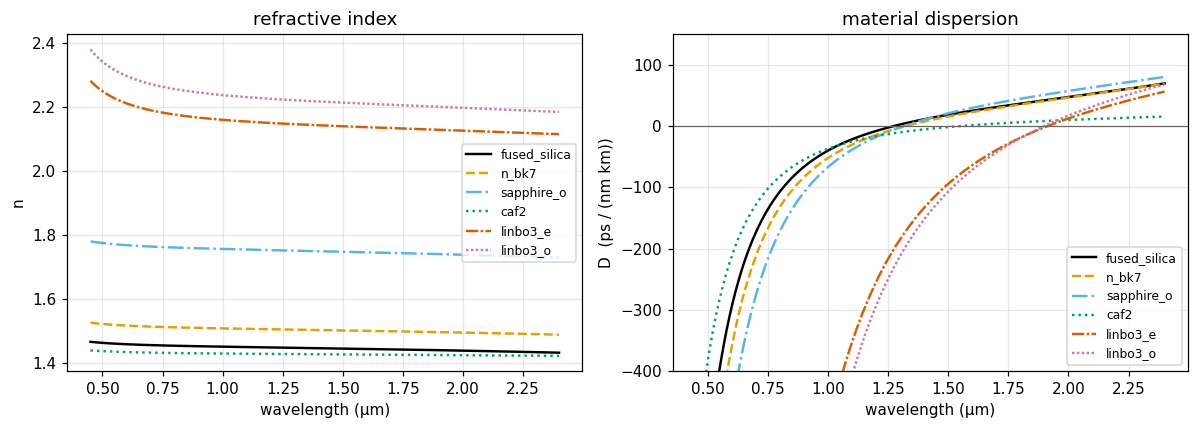

Figure: left, index vs wavelength for six materials (each a different color and line style); every curve falls
with wavelength (normal dispersion). Lithium niobate (about 2.1-2.3) sits far above the glasses (1.42-1.77).
Right, dispersion D: every curve rises through zero, at fused_silica 1.27 um, n_bk7 1.32 um, sapphire_o 1.31 um, caf2 1.55 um, linbo3_e 1.91 um, linbo3_o 1.90 um.
Below its zero-dispersion wavelength a material has D < 0 (red faster); above it, D > 0 (blue faster).


In [4]:
lam_g = np.linspace(0.45, 2.4, 800)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
for i, m in enumerate(M.LIBRARY.values()):
    ok = (lam_g >= m.lam_min_um) & (lam_g <= m.lam_max_um)
    a1.plot(lam_g[ok], M.n(m, lam_g[ok]), color=OKABE_ITO[i], ls=STYLES[i], lw=1.6, label=m.name)
    a2.plot(lam_g[ok], M.D(m, lam_g[ok]), color=OKABE_ITO[i], ls=STYLES[i], lw=1.6, label=m.name)
a1.set_xlabel('wavelength (µm)'); a1.set_ylabel('n'); a1.set_title('refractive index'); a1.legend(fontsize=8)
a2.axhline(0, color='0.4', lw=0.8); a2.set_ylim(-400, 150)
a2.set_xlabel('wavelength (µm)'); a2.set_ylabel('D  (ps / (nm km))'); a2.set_title('material dispersion'); a2.legend(fontsize=8)
plt.tight_layout(); plt.show()
print('Figure: left, index vs wavelength for six materials (each a different color and line style); every curve falls')
print('with wavelength (normal dispersion). Lithium niobate (about 2.1-2.3) sits far above the glasses (1.42-1.77).')
zdw = {k: M.zero_dispersion_um(k) for k in M.LIBRARY}
print('Right, dispersion D: every curve rises through zero, at ' + ', '.join(f'{k} {v:.2f} um' for k, v in zdw.items()) + '.')
print('Below its zero-dispersion wavelength a material has D < 0 (red faster); above it, D > 0 (blue faster).')

---
## 3. Imaging application 1: color blur in a single lens

A thin lens has $1/f \propto n - 1$, so blue focuses closer than red. The spread between the F (486 nm) and C (656 nm) lines is $\Delta f \approx f/V_d$. **High Abbe number = less color blur**: that's why CaF₂ is used in apochromatic microscope objectives.

In [5]:
f_d = 100.0                                                      # mm, design focal length at the d line
for name in ('n_bk7', 'fused_silica', 'caf2', 'sapphire_o'):
    nd = float(M.n(name, M.FRAUNHOFER_UM['d']))
    fF, fC = (f_d*(nd - 1)/(float(M.n(name, M.FRAUNHOFER_UM[k])) - 1) for k in 'FC')
    print(f'{name:13s} V_d = {M.abbe(name):6.2f}   f(F) = {fF:7.3f} mm   f(C) = {fC:7.3f} mm   '
          f'spread = {fC - fF:5.3f} mm   (f/V = {f_d/M.abbe(name):5.3f} mm)')

n_bk7         V_d =  64.17   f(F) =  98.933 mm   f(C) = 100.482 mm   spread = 1.549 mm   (f/V = 1.558 mm)
fused_silica  V_d =  67.82   f(F) =  98.993 mm   f(C) = 100.460 mm   spread = 1.466 mm   (f/V = 1.474 mm)
caf2          V_d =  95.00   f(F) =  99.273 mm   f(C) = 100.322 mm   spread = 1.048 mm   (f/V = 1.053 mm)
sapphire_o    V_d =  72.31   f(F) =  99.054 mm   f(C) = 100.430 mm   spread = 1.376 mm   (f/V = 1.383 mm)


---
## 4. Imaging application 2: reflection loss through windows

Each uncoated surface reflects $R = \left(\frac{n-1}{n+1}\right)^2$. A window has two surfaces, and an imaging path can have many, so losses compound (ignoring multiple reflections).

In [6]:
for name in ('caf2', 'fused_silica', 'n_bk7', 'sapphire_o', 'linbo3_e'):
    R = float(M.fresnel_R(name, 0.8))
    print(f'{name:13s} R = {100*R:5.2f}% per surface  ->  {100*(1 - R)**2:5.1f}% through one window,  '
          f'{100*(1 - R)**10:5.1f}% through five uncoated windows')
print('-> this is why imaging optics are anti-reflection coated, and why the high-index LiNbO3 needs it most')

caf2          R =  3.14% per surface  ->   93.8% through one window,   72.7% through five uncoated windows
fused_silica  R =  3.41% per surface  ->   93.3% through one window,   70.7% through five uncoated windows
n_bk7         R =  4.14% per surface  ->   91.9% through one window,   65.5% through five uncoated windows
sapphire_o    R =  7.58% per surface  ->   85.4% through one window,   45.4% through five uncoated windows
linbo3_e      R = 13.70% per surface  ->   74.5% through one window,   22.9% through five uncoated windows
-> this is why imaging optics are anti-reflection coated, and why the high-index LiNbO3 needs it most


---
## 5. Imaging application 3: the wavelength-to-time map of time-stretch imaging

In the STEAM camera and the photonic time-stretch ADC (Jalali lab, UCLA), a broadband pulse is spread so that **each wavelength arrives at a different time**, $\Delta t = |D|\,L\,\Delta\lambda$. A fast photodetector then reads a spectrum, and so an image line, as a waveform.

**This uses material dispersion only.** Real time-stretch systems use dispersion-compensating fiber or chirped fiber Bragg gratings, whose $D$ (often hundreds of ps/(nm·km), from waveguide design) is far larger than bulk silica's 22. The numbers below show the scaling, not a system design.

In [7]:
D_si = float(M.D('fused_silica', 1.55))
bw_nm, target_ns, fs_GS = 20.0, 10.0, 50.0                       # illustrative: 20 nm optical band, stretch to 10 ns, 50 GS/s ADC
L_needed_km = target_ns*1e3/(abs(D_si)*bw_nm)
print(f'bulk silica at 1550 nm: D = {D_si:.2f} ps/(nm km)')
print(f'to stretch a {bw_nm:.0f} nm band to {target_ns:.0f} ns with material dispersion alone needs L = {L_needed_km:.1f} km of glass')
print(f'with a fiber of |D| = 500 ps/(nm km) (illustrative dispersive fiber) the same stretch needs {target_ns*1e3/(500*bw_nm):.2f} km')
print(f'samples per line at {fs_GS:.0f} GS/s: {target_ns*fs_GS:.0f}  (the number of image pixels the ADC can read per pulse)')
print(f'check with the library: stretch_ps = {M.stretch_ps("fused_silica", L_needed_km, 1.55, bw_nm)/1e3:.2f} ns')

bulk silica at 1550 nm: D = 21.91 ps/(nm km)
to stretch a 20 nm band to 10 ns with material dispersion alone needs L = 22.8 km of glass
with a fiber of |D| = 500 ps/(nm km) (illustrative dispersive fiber) the same stretch needs 1.00 km
samples per line at 50 GS/s: 500  (the number of image pixels the ADC can read per pulse)
check with the library: stretch_ps = 10.00 ns


---
## 6. The same library in C, compiled with gcc

`dgs/c/materials/materials.h` is header-only C99: the same table, the same closed-form derivatives. `materials_cli.c` prints a CSV for one wavelength. Exit code 0 means success, 2 means bad arguments.

In [8]:
HDR = ROOT / 'dgs' / 'c' / 'materials'
WORK = pathlib.Path(tempfile.mkdtemp(prefix='materials_'))
GCC = shutil.which('gcc') or (r'C:\msys64\mingw64\bin\gcc.exe' if os.path.exists(r'C:\msys64\mingw64\bin\gcc.exe') else None)
HAVE_GCC = False
if GCC:
    os.environ['PATH'] = os.path.dirname(GCC) + os.pathsep + os.environ['PATH']
    exe_c = WORK / 'materials_cli.exe'
    cp = subprocess.run([GCC, '-O2', '-Wall', '-Wextra', '-std=c99', str(HDR / 'materials_cli.c'), '-o', str(exe_c), '-lm'], capture_output=True, text=True)
    print('gcc exit code:', cp.returncode, cp.stderr.strip()[:300]); HAVE_GCC = cp.returncode == 0
else:
    print('gcc not found: skipping the C build')
if HAVE_GCC:
    out = subprocess.run([str(exe_c), '1.55'], capture_output=True, text=True).stdout
    print(out)
    worst = 0.0
    for line in out.strip().splitlines()[1:]:
        name, *vals = line.split(',')
        py = [float(M.n(name, 1.55)), float(M.n_group(name, 1.55)), float(M.beta2(name, 1.55)), float(M.D(name, 1.55))]
        worst = max(worst, max(abs(float(v) - p) for v, p in zip(vals, py)))
    print(f'C vs Python, largest difference over all materials and quantities: {worst:.1e}')
    print('bad call exit code:', subprocess.run([str(exe_c), 'blue'], capture_output=True).returncode, '(2 = bad arguments)')

gcc exit code:

0 


name,n,n_group,beta2_ps2_per_km,D_ps_per_nm_km
fused_silica,1.444023621703,1.462596483894,-27.947366138,21.911800219
n_bk7,1.500652043020,1.520071676865,-24.631835098,19.312297519
sapphire_o,1.746181625059,1.773174476941,-32.524902006,25.500762805
caf2,1.426024327216,1.433263556998,-0.072397218,0.056762178
linbo3_e,2.137559649786,2.182319433194,99.487258576,-78.001802516
linbo3_o,2.211111008654,2.263675238317,112.191985118,-87.962792344

C vs Python, largest difference over all materials and quantities: 4.9e-10
bad call exit code: 2 (2 = bad arguments)


---
## 7. The same library in CUDA, compiled with nvcc

`dgs/cuda/materials.cu` includes the **same header**: the `MAT_FN` macro marks the functions `__host__ __device__` when nvcc compiles them, so one source of truth runs on the CPU and the GPU. Each GPU thread evaluates one wavelength for one material; the grid is 100 000 wavelengths × 6 materials. On Windows, nvcc needs MSVC loaded by `vcvars64.bat`; the RTX 4060 is `sm_89`.

In [9]:
NVCC = shutil.which('nvcc') or (glob.glob(r'C:\Program Files\NVIDIA GPU Computing Toolkit\CUDA\v*\bin\nvcc.exe') or [None])[-1]
VCVARS = (glob.glob(r'C:\Program Files\Microsoft Visual Studio\*\*\VC\Auxiliary\Build\vcvars64.bat') or [None])[0]
print('nvcc:', NVCC, '\nvcvars64.bat:', VCVARS)
HAVE_CUDA = False
if NVCC and (VCVARS or os.name != 'nt'):
    exe_cu = WORK / 'materials_cuda.exe'
    build = f'"{NVCC}" -O2 -arch=sm_89 -I"{HDR}" "{ROOT / "dgs" / "cuda" / "materials.cu"}" -o "{exe_cu}"'
    if os.name == 'nt':
        bat = WORK / 'build.bat'; bat.write_text(f'@echo off\ncall "{VCVARS}" >nul 2>nul\n{build}\nexit /b %ERRORLEVEL%\n')
        cp = subprocess.run(['cmd', '/c', str(bat)], capture_output=True, text=True, timeout=600)
    else:
        cp = subprocess.run(build, shell=True, capture_output=True, text=True, timeout=600)
    print('nvcc exit code:', cp.returncode); HAVE_CUDA = cp.returncode == 0
    if not HAVE_CUDA: print(cp.stdout[-600:], cp.stderr[-600:])
else:
    print('nvcc or MSVC not found: skipping the CUDA build')
if HAVE_CUDA:
    npts, lo, hi = 100_000, 0.4, 2.5
    rr = subprocess.run([str(exe_cu), str(WORK / 'grid.bin'), str(npts), str(lo), str(hi)], capture_output=True, text=True)
    print('run exit code:', rr.returncode, rr.stderr.strip())
    if rr.returncode == 0:
        grid = np.fromfile(WORK / 'grid.bin', dtype=np.float64).reshape(len(M.LIBRARY), 2, npts)
        lam_cu = lo + (hi - lo)*np.arange(npts)/(npts - 1)
        t0 = time.perf_counter(); worst_n = worst_b = 0.0
        for i, m in enumerate(M.LIBRARY.values()):
            ok = (lam_cu >= m.lam_min_um) & (lam_cu <= m.lam_max_um)
            worst_n = max(worst_n, np.max(np.abs(grid[i, 0, ok] - M.n(m, lam_cu[ok]))))
            worst_b = max(worst_b, np.max(np.abs(grid[i, 1, ok] - M.beta2(m, lam_cu[ok]))))
        t_np = (time.perf_counter() - t0)*1e3
        print(f'GPU kernel: {float(rr.stdout):.3f} ms for {npts*len(M.LIBRARY):,} (wavelength, material) points')
        print(f'NumPy, same grid (plus the comparison): {t_np:.1f} ms')
        print(f'CUDA vs Python: max |dn| = {worst_n:.1e}, max |d beta2| = {worst_b:.1e} ps^2/km')

nvcc: C:\Program Files\NVIDIA GPU Computing Toolkit\CUDA\v13.0\bin\nvcc.EXE 
vcvars64.bat: C:\Program Files\Microsoft Visual Studio\2022\Community\VC\Auxiliary\Build\vcvars64.bat


nvcc exit code: 0
run exit code: 0 


GPU kernel: 0.935 ms for 600,000 (wavelength, material) points
NumPy, same grid (plus the comparison): 99.1 ms
CUDA vs Python: max |dn| = 0.0e+00, max |d beta2| = 1.4e-12 ps^2/km


---
## 8. A grammar for units and signs (for grammar nerds)

Dispersion numbers go wrong in two ways: a missing unit conversion ($\beta_2$ in s²/m vs ps²/km differ by $10^{27}$) or a flipped sign ($D$ and $\beta_2$ have **opposite** signs). The library follows four rules, the way a grammar fixes word order:

1. **The unit is part of the name.** `lam_um`, `length_km`, `bandwidth_nm`: you can't pass nanometers to a function that says micrometers without the name looking wrong.
2. **One conversion, at the end.** Formulas are written in SI; the last line converts (`*1e27` for ps²/km).
3. **The sign convention is a law, tested.** $D = -\dfrac{2\pi c}{\lambda^2}\beta_2$. Normal dispersion means $\beta_2 > 0$ and $D < 0$: red travels faster.
4. **Names are nouns, functions are what they return.** `n(...)`, `beta2(...)`, `abbe(...)`, not `calc_stuff(...)`. Docstrings are full sentences that state the units.

In [10]:
lam_t = np.array([0.6, 1.0, 1.55, 2.0])
lhs = M.D('fused_silica', lam_t)
rhs = -2*np.pi*M.C0/(lam_t*1e-6)**2 * (M.beta2('fused_silica', lam_t)*1e-27) * 1e6
for l_, a_, b_, b2 in zip(lam_t, lhs, rhs, M.beta2('fused_silica', lam_t)):
    regime = 'normal (red faster)' if b2 > 0 else 'anomalous (blue faster)'
    print(f'{l_:4.2f} um: D = {a_:+8.3f}, -2 pi c beta2 / lam^2 = {b_:+8.3f} ps/(nm km)   beta2 = {b2:+8.2f} ps^2/km  {regime}')
print('rule 3 holds:', bool(np.allclose(lhs, rhs, rtol=1e-12)))

0.60 um: D = -292.635, -2 pi c beta2 / lam^2 = -292.635 ps/(nm km)   beta2 =   +55.93 ps^2/km  normal (red faster)
1.00 um: D =  -39.855, -2 pi c beta2 / lam^2 =  -39.855 ps/(nm km)   beta2 =   +21.16 ps^2/km  normal (red faster)
1.55 um: D =  +21.912, -2 pi c beta2 / lam^2 =  +21.912 ps/(nm km)   beta2 =   -27.95 ps^2/km  anomalous (blue faster)
2.00 um: D =  +47.379, -2 pi c beta2 / lam^2 =  +47.379 ps/(nm km)   beta2 =  -100.61 ps^2/km  anomalous (blue faster)
rule 3 holds: True


## Sources

[1] I. H. Malitson, "Interspecimen comparison of the refractive index of fused silica," *J. Opt. Soc. Am.*, vol. 55, no. 10, pp. 1205–1209, 1965.
[2] SCHOTT AG, "Optical glass data sheets: N-BK7."
[3] I. H. Malitson and M. J. Dodge, "Refractive index and birefringence of synthetic sapphire," *J. Opt. Soc. Am.*, vol. 62, p. 1405, 1972.
[4] I. H. Malitson, "A redetermination of some optical properties of calcium fluoride," *Appl. Opt.*, vol. 2, no. 11, pp. 1103–1107, 1963.
[5] D. E. Zelmon, D. L. Small, and D. Jundt, "Infrared corrected Sellmeier coefficients for congruently grown lithium niobate and 5 mol.% magnesium oxide-doped lithium niobate," *J. Opt. Soc. Am. B*, vol. 14, no. 12, pp. 3319–3322, 1997.
[6] K. Goda, K. K. Tsia, and B. Jalali, "Serial time-encoded amplified imaging for real-time observation of fast dynamic phenomena," *Nature*, vol. 458, pp. 1145–1149, 2009.

The coefficients were entered from memory and are checked in `tests/test_materials.py` against published index values (N-BK7 $n_d$ = 1.5168, fused silica $n$(1550 nm) = 1.4440, Abbe numbers, and the silica zero-dispersion wavelength). Confirm them against the original papers before a design.